In [9]:
import pandas as pd

df = pd.read_csv("Depot_sales.csv", header=0, parse_dates=["date"], index_col="date")

print(df["Product_A"])

date
2020-01-01    44.0
2020-01-02    40.0
2020-01-03    40.0
2020-01-04    42.0
2020-01-05    41.0
              ... 
2023-12-27    45.0
2023-12-28    44.0
2023-12-29    43.0
2023-12-30    45.0
2023-12-31    47.0
Name: Product_A, Length: 1461, dtype: float64


In [10]:
from scipy import stats 

print("Are these products sale values normally distributed")

test_a, pa = stats.shapiro(df["Product_A"])
test_b, pb = stats.shapiro(df["Product_B"])
test_c, pc = stats.shapiro(df["Product_C"])

if test_a > 0.05:
    print("Product A's sales are normally distributed")
else:
    print("Product A's sales are not normally distributed")

if test_b > 0.05:
    print("Product B's sales are normally distributed")
else:
    print("Product B's sales are not normally distributed")

if test_c > 0.05:
    print("Product C's sales are normally distributed")
else:
    print("Product C's sales are not normally distributed")

Are these products sale values normally distributed
Product A's sales are normally distributed
Product B's sales are normally distributed
Product C's sales are normally distributed


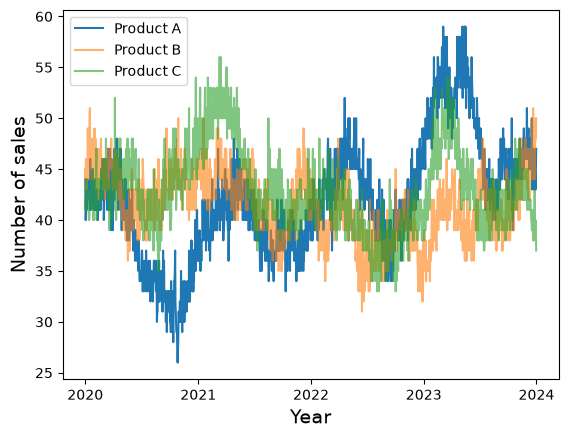

In [13]:
from matplotlib import pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], label="Product A")
ax.plot(df.index, df["Product_B"], label ="Product B",alpha = 0.6)
ax.plot(df.index, df["Product_C"], label="Product C", alpha= 0.6)
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()



### I perform the one way ANOVA to identify whether the means of the different product are significantly different. I test at p = 0.05 level of significance

In [14]:
stats.f_oneway(df["Product_A"], df["Product_B"], df["Product_C"])

F_onewayResult(statistic=np.float64(47.323767913712196), pvalue=np.float64(4.6393799294154e-21))

### As p is less than 0.05 the null hypothesis is rejected showing that the mean values of the three products are different to a statistically significant degree.

In [17]:
import numpy as np

#df_2020 = df[df["date"].dt.year == 2020]

yearly_means = (
    df.groupby(df.index.year)[["Product_A", "Product_B", "Product_C"]]
    .mean()
    .rename_axis("Year")
    .round(2)
)
yearly_means

,Product_A,Product_B,Product_C
Year,,,
2020,37.40,43.19,43.27
2021,39.37,42.24,45.15
2022,42.29,38.50,39.62
2023,48.60,41.13,43.45


### Performing a simple linear regression fit using generalised least squares to predict future price behaviour.

Slope: 0.0081 days (2.97 per year)
Intercept: 35.99
R2: 0.347, p-value: 2.52e-137


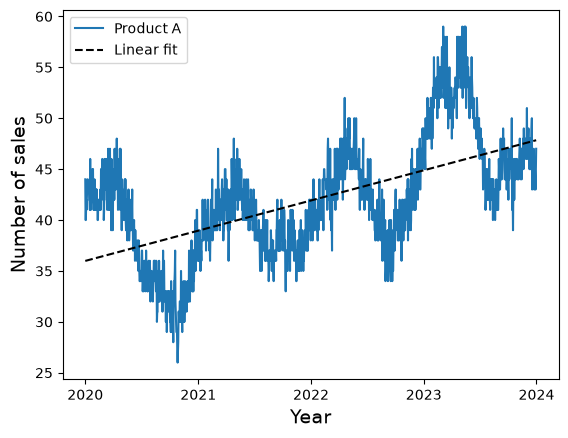

The RMSE is  0.17373799440593587


In [29]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

x = (df.index - df.index[0]).days

result = stats.linregress(x, df["Product_A"])
print(f"Slope: {result.slope:.4f} days ({result.slope * 365.25:.2f} per year)")
print(f"Intercept: {result.intercept:.2f}")
print(f"R2: {result.rvalue**2:.3f}, p-value: {result.pvalue:.3g}")


fit_line = result.intercept + result.slope * x
RMSE = np.sqrt(1/sum(x) * sum((df["Product_A"]-fit_line)**2))
#print(f"least squares mean: {np.mean(fit_line):.2f}")
      
fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], label="Product A",)
ax.plot(df.index, fit_line, label="Linear fit", color="black", linestyle="--")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()
print("The RMSE is ", RMSE)

Slope: -0.0027 days (-0.98 per year)
Intercept: 43.21
R2: 0.116, p-value: 7.15e-41


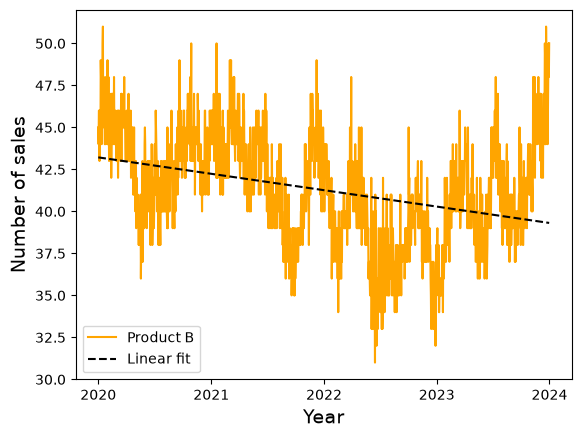

The MSE is  0.013303703394041947


In [ ]:
x = (df.index - df.index[0]).days

result = stats.linregress(x, df["Product_B"])
print(f"Slope: {result.slope:.4f} days ({result.slope * 365.25:.2f} per year)")
print(f"Intercept: {result.intercept:.2f}")
print(f"R2: {result.rvalue**2:.3f}, p-value: {result.pvalue:.3g}")


fit_line = result.intercept + result.slope * x
RMSE = np.sqrt(1/sum(x) * sum((df["Product_B"]-fit_line)**2))
#print(f"least squares mean: {np.mean(fit_line):.2f}")
      
fig, ax = plt.subplots()
ax.plot(df.index, df["Product_B"], label="Product B", color="orange")
ax.plot(df.index, fit_line, label="Linear fit", color="black", linestyle="--")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()
print("The RMSE is ", RMSE)

Slope: -0.0022 days (-0.81 per year)
Intercept: 44.48
R2: 0.055, p-value: 1.47e-19


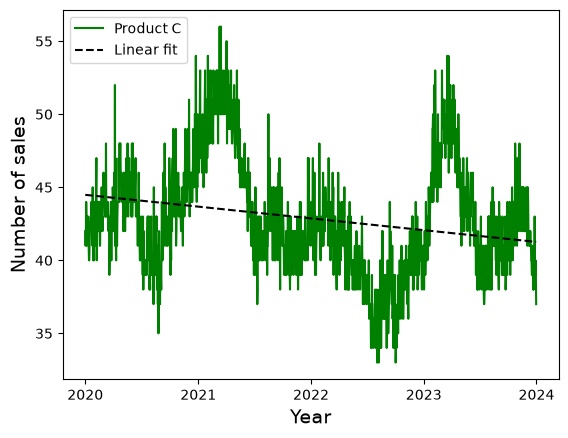

The MSE is  0.020553603414739944


In [ ]:
x = (df.index - df.index[0]).days

result = stats.linregress(x, df["Product_C"])
print(f"Slope: {result.slope:.4f} days ({result.slope * 365.25:.2f} per year)")
print(f"Intercept: {result.intercept:.2f}")
print(f"R2: {result.rvalue**2:.3f}, p-value: {result.pvalue:.3g}")


fit_line = result.intercept + result.slope * x
RMSE = np.sqrt(1/sum(x) * sum((df["Product_C"]-fit_line)**2))

      
fig, ax = plt.subplots()
ax.plot(df.index, df["Product_C"], label="Product C", color="green")
ax.plot(df.index, fit_line, label="Linear fit", color="black", linestyle="--")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()
print("The RMSE is ", RMSE)

### The linear fits do give good results for mean (based off the regression fit) and low p-values but clearly miss a significant amount of the behaviour of the curve, though they are cheap to calculate.

### Using a non-linear curve fit instead

In [21]:
from scipy.optimize import curve_fit
import numpy as np

x = (df.index - df.index[0]).days

def func(x, a, b, c, d, const):
    return a * np.sin(b*x) + c * np.cos(d*x) + const

NonL_fit = curve_fit(func, x, df["Product_A"], p0=[0.1, 0.1, 0.1, 0.1, 0.2], method="trf")

print(NonL_fit)
NonL_params = NonL_fit[0]
print(NonL_params)
MSE = 1/sum(x) * sum((df["Product_A"]-func(x, NonL_params[0], NonL_params[1], NonL_params[2], NonL_params[3]))**2)

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], alpha=0.5, label="Actual")
ax.plot(df.index, func(x, NonL_params[0], NonL_params[1], NonL_params[2], NonL_params[3]), label="Non-linear least squares fit")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()
print("MSE is ", MSE)

RuntimeError: Optimal parameters not found: The maximum number of function evaluations is exceeded.

### Kernel ridge regression

{'alpha': 1, 'gamma': 20}


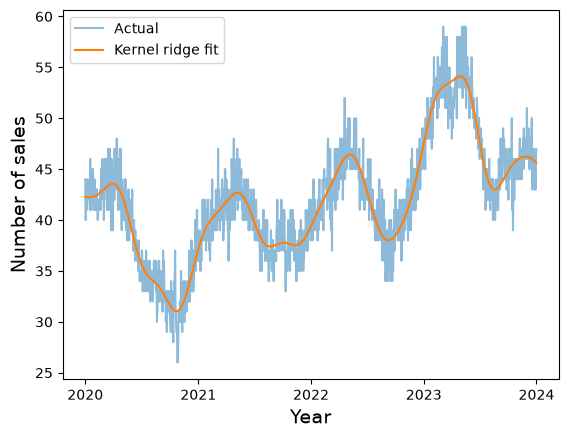

RMSE is  0.06950246650361962


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

a = np.asarray((df.index - df.index[0]).days, dtype=float)
X = (a / 365.25).reshape(-1, 1)
y = df["Product_A"].to_numpy(dtype=float)
y_mean = y.mean() #The central target??

grid = GridSearchCV(
    KernelRidge(kernel="rbf"),
    param_grid={"alpha": [0.01, 0.1, 1, 10], "gamma": [1, 5, 20, 50, 100]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
)
grid.fit(X, y-y_mean)
print(grid.best_params_)

best = grid.best_estimator_
fitted = best.predict(X) + y_mean
RMSE = np.sqrt(1/sum(x) * sum((df["Product_A"]-fitted)**2))


fig, ax = plt.subplots()
ax.plot(df.index, y, alpha=0.5, label="Actual")
ax.plot(df.index, fitted, label="Kernel ridge fit")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()

print("RMSE is ", RMSE)

### Holt-Winters exponential curve smoothing used to statistical model the time series

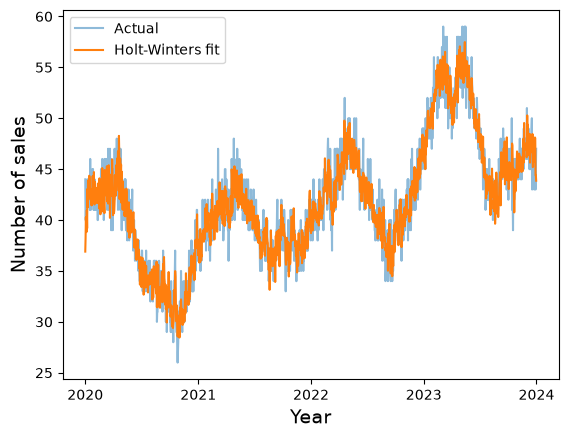

RMSE is  0.06443771976653731


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

df = pd.read_csv("Depot_sales.csv", parse_dates=["date"], index_col="date")
df = df.asfreq("D")                      # daily frequency on the index

#split = int(len(df) * 0.8)
#train, test = df.iloc[:split], df.iloc[split:]

HW_model = ExponentialSmoothing(
    df["Product_A"],
    trend="add",                         # linear trend
    damped_trend=True,                   # stops the trend extrapolating forever
    seasonal="add",                      # additive seasonality
    seasonal_periods=365,                # must be an integer
    initialization_method="heuristic",   # Best for long term periods
).fit()

fitted = HW_model.fittedvalues              #fitted curve
RMSE = np.sqrt(1/sum(x) * sum((df["Product_A"]-fitted)**2))

#print(HW_model.params)                      

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], alpha=0.5, label="Actual")
ax.plot(df.index, fitted, label="Holt-Winters fit")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()
print("RMSE is ", RMSE)

